# Machine Learning Assignment 2 — Question 2
## Multiclass SAMME AdaBoost implemented from scratch

Run all cells from top to bottom in Google Colab or Jupyter. This notebook implements the SAMME boosting algorithm directly; it does **not** use `AdaBoostClassifier`.

**Setup**
- Roll number: `m24ma2007`; numeric seed: `242007`
- Olivetti Faces: 40 identities, 400 images, each 64 × 64
- Raw flattened pixels only (4,096 features); no PCA or other dimensionality reduction
- Per identity: 6 train, 2 validation, 2 test images
- The split uses the same seed and split procedure as the Q1 notebook and is saved/reused.
- Training uses clean images only; the masked test set is for evaluation only.

All reported metrics and plots are computed when you execute the notebook. Do not treat unexecuted results as measurements.

## 0. Imports and configuration

In [1]:
# If needed in a fresh environment:
# %pip install -q numpy pandas matplotlib scikit-learn

import os, json, time, itertools, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from IPython.display import display

ROLL_NUMBER = "m24ma2007"
SEED = int("".join(ch for ch in ROLL_NUMBER if ch.isdigit()))
assert SEED == 242007
OUT_DIR = "q2_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
print("Seed:", SEED, "| Output:", os.path.abspath(OUT_DIR))

Seed: 242007 | Output: /home/M24MA2009/pawanassign/q2_outputs


## 1. Load the data and reuse the Q1 split

If the Q1 split file is available in the current runtime, load it. Otherwise, regenerate the exact same split deterministically using the specified seed and per-identity 6/2/2 procedure, then save it. Keep this file with the Q1 outputs and use it for all assignment questions.

In [2]:
faces = fetch_olivetti_faces(shuffle=False)
X_images = faces.images.astype(np.float32)
y = faces.target.astype(np.int64)
X = X_images.reshape(len(X_images), -1)
assert X_images.shape == (400, 64, 64) and X.shape == (400, 4096)
assert len(np.unique(y)) == 40
assert all(np.sum(y == c) == 10 for c in np.unique(y))

# Reuse a saved Q1 split if present; otherwise create the same deterministic split.
candidate_paths = [
    os.path.join("q1_outputs", "olivetti_split_seed_242007.npz"),
    "olivetti_split_seed_242007.npz",
]
split_path = next((p for p in candidate_paths if os.path.exists(p)), None)
if split_path is not None:
    split_data = np.load(split_path, allow_pickle=False)
    train_idx = split_data["train_idx"].astype(int)
    val_idx = split_data["val_idx"].astype(int)
    test_idx = split_data["test_idx"].astype(int)
    print("Loaded saved split from:", split_path)
else:
    split_rng = np.random.default_rng(SEED)
    train_idx, val_idx, test_idx = [], [], []
    for identity in sorted(np.unique(y)):
        identity_idx = np.flatnonzero(y == identity)
        shuffled = split_rng.permutation(identity_idx)
        train_idx.extend(shuffled[:6].tolist())
        val_idx.extend(shuffled[6:8].tolist())
        test_idx.extend(shuffled[8:10].tolist())
    train_idx = np.asarray(train_idx, dtype=np.int64)
    val_idx = np.asarray(val_idx, dtype=np.int64)
    test_idx = np.asarray(test_idx, dtype=np.int64)
    split_path = os.path.join(OUT_DIR, "olivetti_split_seed_242007.npz")
    np.savez_compressed(split_path, train_idx=train_idx, val_idx=val_idx, test_idx=test_idx,
                        seed=np.asarray(SEED), roll_number=np.asarray(ROLL_NUMBER))
    print("Generated and saved split to:", split_path)

assert len(train_idx) == 240 and len(val_idx) == 80 and len(test_idx) == 80
assert not (set(train_idx) & set(val_idx))
assert not (set(train_idx) & set(test_idx))
assert not (set(val_idx) & set(test_idx))
for identity in np.unique(y):
    assert np.sum(y[train_idx] == identity) == 6
    assert np.sum(y[val_idx] == identity) == 2
    assert np.sum(y[test_idx] == identity) == 2

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

X_images_masked = X_images.copy()
X_images_masked[:, 24:40, 24:40] = 0.0
X_masked = X_images_masked.reshape(len(X_images_masked), -1)
X_test_masked = X_masked[test_idx]
classes = np.unique(y_train)
K = len(classes)
print("Shapes:", X_train.shape, X_val.shape, X_test.shape, "| K =", K)

Loaded saved split from: q1_outputs/olivetti_split_seed_242007.npz
Shapes: (240, 4096) (80, 4096) (80, 4096) | K = 40


## 2. Q2(a): log one complete SAMME round on a three-class example

This example has at most 10 samples and logs the initial weights, weak learner predictions, weighted error, learner weight \(\alpha_t\), and updated normalised sample weights. The same weight update rule is used by the Olivetti implementation below.

In [3]:
# Tiny, deterministic three-class dataset: 9 samples, 2 features.
X_tiny = np.array([
    [0.0, 0.0], [0.2, 0.1], [0.1, 0.3],
    [1.0, 0.0], [1.2, 0.2], [0.9, 0.3],
    [0.0, 1.0], [0.2, 1.2], [0.3, 0.9]
])
y_tiny = np.array([0, 0, 1, 1, 1, 2, 2, 2, 0])
tiny_classes = np.unique(y_tiny)
tiny_K = len(tiny_classes)
w0 = np.full(len(y_tiny), 1.0 / len(y_tiny))

tiny_learner = DecisionTreeClassifier(max_depth=1, random_state=SEED)
tiny_learner.fit(X_tiny, y_tiny, sample_weight=w0)
tiny_pred = tiny_learner.predict(X_tiny)
tiny_miss = (tiny_pred != y_tiny)
tiny_error = float(np.sum(w0 * tiny_miss))
tiny_threshold = 1.0 - 1.0 / tiny_K

if tiny_error >= tiny_threshold:
    print("Tiny example's learner is not better than random; SAMME would stop without updating.")
    tiny_alpha = None
    w1 = w0.copy()
else:
    eps = np.finfo(float).eps
    if tiny_error <= eps:
        tiny_alpha = float(np.log((1.0 - eps) / eps) + np.log(tiny_K - 1))
        w1 = w0.copy()
    else:
        tiny_alpha = float(np.log((1.0 - tiny_error) / tiny_error) + np.log(tiny_K - 1))
        w1 = w0 * np.exp(tiny_alpha * tiny_miss.astype(float))
        w1 /= w1.sum()

tiny_log = pd.DataFrame({
    "sample": np.arange(len(y_tiny)),
    "true_class": y_tiny,
    "weak_prediction": tiny_pred,
    "misclassified": tiny_miss,
    "initial_weight": w0,
    "updated_weight": w1
})
print("Initial sample weights:", w0)
print("Weak learner predictions:", tiny_pred)
print("Weighted error:", tiny_error)
print("Random-guess threshold (1 - 1/K):", tiny_threshold)
print("SAMME alpha:", tiny_alpha)
print("Updated normalised sample weights:", w1)
display(tiny_log)
tiny_log.to_csv(os.path.join(OUT_DIR, "q2a_tiny_samme_round.csv"), index=False)

Initial sample weights: [0.11111111 0.11111111 0.11111111 0.11111111 0.11111111 0.11111111
 0.11111111 0.11111111 0.11111111]
Weak learner predictions: [0 0 0 1 1 0 0 0 0]
Weighted error: 0.4444444444444444
Random-guess threshold (1 - 1/K): 0.6666666666666667
SAMME alpha: 0.9162907318741552
Updated normalised sample weights: [0.06666667 0.06666667 0.16666667 0.06666667 0.06666667 0.16666667
 0.16666667 0.16666667 0.06666667]


,sample,true_class,weak_prediction,misclassified,initial_weight,updated_weight
0,0,0,0,False,0.111111,0.066667
1,1,0,0,False,0.111111,0.066667
2,2,1,0,True,0.111111,0.166667
3,3,1,1,False,0.111111,0.066667
4,4,1,1,False,0.111111,0.066667
5,5,2,0,True,0.111111,0.166667
6,6,2,0,True,0.111111,0.166667
7,7,2,0,True,0.111111,0.166667
8,8,0,0,False,0.111111,0.066667


## 3. SAMME classifier implemented from scratch

For each round, fit a decision tree using the current sample weights. Compute weighted misclassification error \(\epsilon_t\). If \(\epsilon_t \ge 1-1/K\), stop and reject that learner because it is no better than random multiclass prediction. Otherwise calculate

\[
\alpha_t = \log\left(\frac{1-\epsilon_t}{\epsilon_t}\right)+\log(K-1).
\]

Update weights by multiplying misclassified samples by \(e^{\alpha_t}\), then normalise. If a learner classifies all training samples correctly, record a finite alpha using machine precision and stop after adding it. Scores are \(S_k(x)=\sum_t \alpha_t\mathbf{1}[h_t(x)=k]\); confidence follows the assignment's normalised weighted vote \(q_k(x)=S_k(x)/\sum_t\alpha_t\).

In [4]:
class ScratchSAMME:
    def __init__(self, max_depth=1, n_estimators=50, random_state=0):
        self.max_depth = max_depth
        self.n_estimators = n_estimators
        self.random_state = random_state
        self.estimators_ = []
        self.estimator_weights_ = []
        self.round_logs_ = []
        self.classes_ = None
        self.n_features_in_ = None
        self.stop_reason_ = None

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        K = len(self.classes_)
        n = len(y)
        self.n_features_in_ = X.shape[1]
        sample_weight = np.full(n, 1.0 / n, dtype=float)
        self.estimators_, self.estimator_weights_, self.round_logs_ = [], [], []
        self.stop_reason_ = "requested_rounds_reached"

        random_threshold = 1.0 - 1.0 / K
        eps = np.finfo(float).eps

        for t in range(self.n_estimators):
            estimator = DecisionTreeClassifier(
                max_depth=self.max_depth,
                random_state=self.random_state + t
            )
            estimator.fit(X, y, sample_weight=sample_weight)
            pred = estimator.predict(X)
            incorrect = (pred != y)
            err = float(np.sum(sample_weight * incorrect))

            # Reject a learner that is not better than random multiclass prediction.
            if err >= random_threshold:
                self.stop_reason_ = f"stopped_round_{t+1}_weak_learner_not_better_than_random"
                break

            # Finite numeric alpha for perfect fit; stop after adding this learner.
            perfect = err <= eps
            safe_err = max(err, eps)
            alpha = float(np.log((1.0 - safe_err) / safe_err) + np.log(K - 1))

            self.estimators_.append(estimator)
            self.estimator_weights_.append(alpha)

            if not perfect:
                sample_weight *= np.exp(alpha * incorrect.astype(float))
                sample_weight /= sample_weight.sum()

            self.round_logs_.append({
                "round": t + 1,
                "weighted_error": err,
                "alpha": alpha,
                "max_sample_weight": float(sample_weight.max()),
                "top10_sample_weight_total": float(np.sort(sample_weight)[-min(10, n):].sum()),
                "training_accuracy": float(accuracy_score(y, pred)),
                "perfect_learner": bool(perfect)
            })

            if perfect:
                self.stop_reason_ = f"stopped_round_{t+1}_perfect_learner"
                break

        if len(self.estimators_) == 0:
            self.stop_reason_ = self.stop_reason_ or "no_accepted_weak_learners"
        return self

    def decision_function(self, X):
        X = np.asarray(X)
        if not self.estimators_:
            raise RuntimeError("SAMME has no accepted weak learners.")
        scores = np.zeros((len(X), len(self.classes_)), dtype=float)
        class_to_col = {c: i for i, c in enumerate(self.classes_)}
        for estimator, alpha in zip(self.estimators_, self.estimator_weights_):
            pred = estimator.predict(X)
            for c in np.unique(pred):
                scores[pred == c, class_to_col[c]] += alpha
        return scores

    def predict_weighted_vote(self, X):
        scores = self.decision_function(X)
        return self.classes_[np.argmax(scores, axis=1)]

    def predict_proba(self, X):
        scores = self.decision_function(X)
        total = np.sum(self.estimator_weights_)
        if total <= 0:
            return np.full_like(scores, 1.0 / len(self.classes_))
        # Assignment specifies normalised weighted vote q_k = S_k / sum(alpha_t).
        return scores / total

    def predict_confidence(self, X):
        q = self.predict_proba(X)
        return q.max(axis=1)

    def get_round_log(self):
        return pd.DataFrame(self.round_logs_)

print("ScratchSAMME class defined.")

ScratchSAMME class defined.


## 4. Q2(b): choose weak-learner depth and number of rounds using clean validation accuracy only

Try depths 1, 2, 3, 4 and requested rounds 10, 25, 50, 100. Each fit starts with uniform sample weights. Select by clean validation accuracy; ties prefer fewer rounds, then shallower depth. The selected model is frozen after this selection.

In [5]:
DEPTHS = [1, 2, 3, 4]
ROUND_COUNTS = [10, 25, 50, 100]
boost_grid_rows = []
boost_models = {}
boost_fit_times = {}

for depth in DEPTHS:
    for rounds in ROUND_COUNTS:
        model = ScratchSAMME(max_depth=depth, n_estimators=rounds, random_state=SEED + 5000)
        start = time.perf_counter()
        model.fit(X_train, y_train)
        elapsed = time.perf_counter() - start
        boost_models[(depth, rounds)] = model
        boost_fit_times[(depth, rounds)] = elapsed
        pred_train = model.predict_weighted_vote(X_train)
        pred_val = model.predict_weighted_vote(X_val)
        boost_grid_rows.append({
            "max_depth": depth,
            "requested_rounds": rounds,
            "actual_rounds": len(model.estimators_),
            "train_accuracy": accuracy_score(y_train, pred_train),
            "validation_accuracy": accuracy_score(y_val, pred_val),
            "fit_time_seconds": elapsed,
            "stop_reason": model.stop_reason_
        })

boost_grid = pd.DataFrame(boost_grid_rows)
display(boost_grid)
boost_grid.to_csv(os.path.join(OUT_DIR, "q2b_samme_validation_grid.csv"), index=False)

# Sort by validation accuracy descending, then fewer requested rounds, then shallower depth.
ranked = boost_grid.sort_values(
    ["validation_accuracy", "requested_rounds", "max_depth"],
    ascending=[False, True, True],
    kind="stable"
)
selected = ranked.iloc[0]
BEST_BOOST_DEPTH = int(selected["max_depth"])
BEST_BOOST_ROUNDS = int(selected["requested_rounds"])
boost = boost_models[(BEST_BOOST_DEPTH, BEST_BOOST_ROUNDS)]
print("Selected boosting configuration:", {
    "max_depth": BEST_BOOST_DEPTH,
    "requested_rounds": BEST_BOOST_ROUNDS,
    "actual_rounds": len(boost.estimators_),
    "validation_accuracy": float(selected["validation_accuracy"]),
    "stop_reason": boost.stop_reason_
})

,max_depth,requested_rounds,actual_rounds,train_accuracy,validation_accuracy,fit_time_seconds,stop_reason
0,1,10,10,0.050000,0.0500,1.336683,requested_rounds_reached
1,1,25,25,0.050000,0.0375,2.630994,requested_rounds_reached
2,1,50,50,0.166667,0.0625,5.180605,requested_rounds_reached
3,1,100,100,0.208333,0.1125,9.985974,requested_rounds_reached
4,2,10,10,0.091667,0.0750,1.984041,requested_rounds_reached
5,2,25,25,0.191667,0.1000,4.954904,requested_rounds_reached
6,2,50,50,0.283333,0.0750,9.786936,requested_rounds_reached
7,2,100,100,0.320833,0.0750,19.763377,requested_rounds_reached
8,3,10,10,0.233333,0.1375,2.935228,requested_rounds_reached
9,3,25,25,0.433333,0.2000,7.382775,requested_rounds_reached


Selected boosting configuration: {'max_depth': 4, 'requested_rounds': 100, 'actual_rounds': 100, 'validation_accuracy': 0.3875, 'stop_reason': 'requested_rounds_reached'}


### Plot selected model's training diagnostics

Plot weighted training error, learner weight \(\alpha_t\), maximum sample weight, and total weight on the 10 heaviest training samples over rounds. These values are measured from the actual boosting run.

,round,weighted_error,alpha,max_sample_weight,top10_sample_weight_total,training_accuracy,perfect_learner
0,1,0.875000,1.717651,0.004643,0.046429,0.125000,False
1,2,0.860714,1.842326,0.005259,0.052593,0.125000,False
2,3,0.842220,1.988723,0.006088,0.060885,0.125000,False
3,4,0.814195,2.186061,0.007291,0.072910,0.137500,False
4,5,0.722147,2.708426,0.009844,0.098439,0.183333,False
...,...,...,...,...,...,...,...
95,96,0.649605,3.046258,0.058198,0.385271,0.158333,False
96,97,0.662327,2.989880,0.067684,0.377459,0.125000,False
97,98,0.680295,2.908435,0.069817,0.325994,0.125000,False
98,99,0.662972,2.986995,0.044394,0.308643,0.125000,False


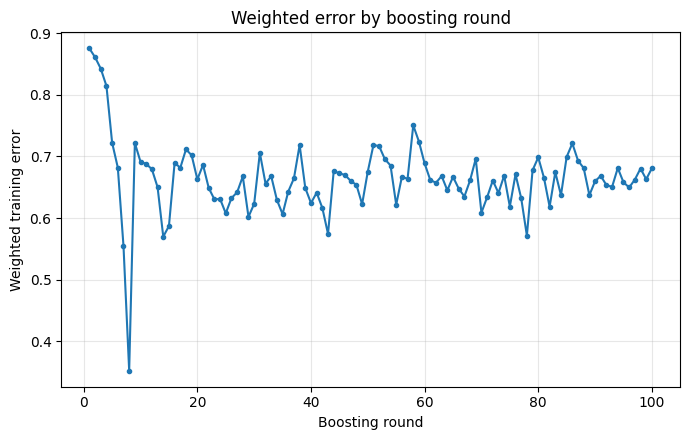

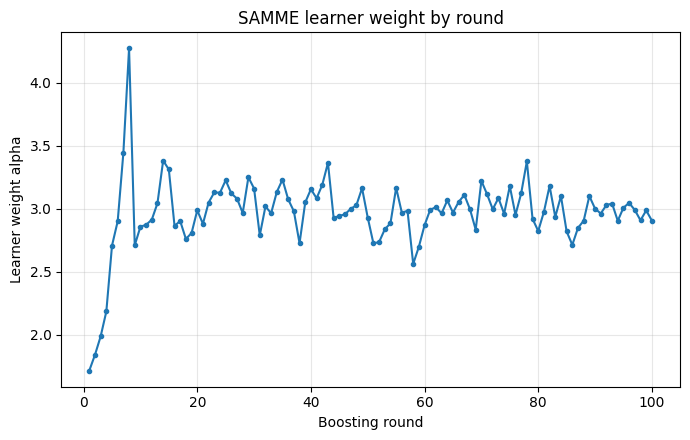

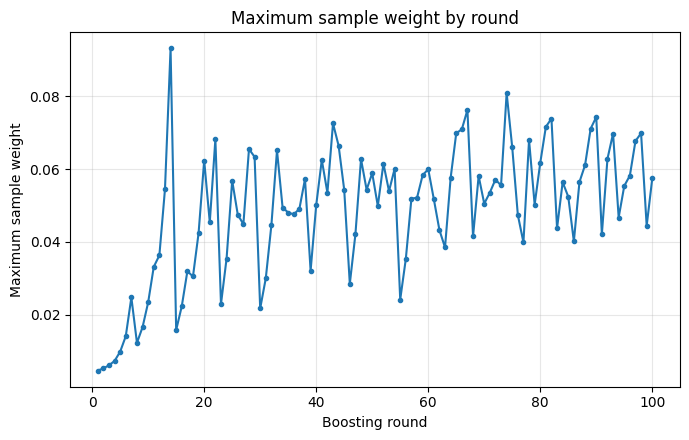

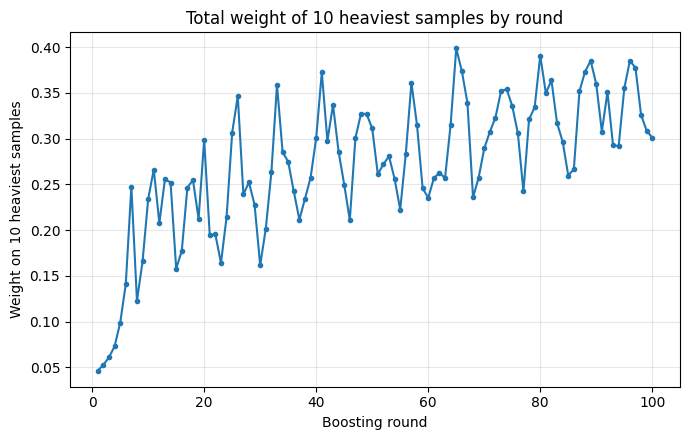

In [6]:
selected_log = boost.get_round_log()
display(selected_log)
selected_log.to_csv(os.path.join(OUT_DIR, "q2b_selected_boosting_round_log.csv"), index=False)

plot_specs = [
    ("weighted_error", "Weighted training error", "Weighted error by boosting round", "q2b_weighted_error.png"),
    ("alpha", "Learner weight alpha", "SAMME learner weight by round", "q2b_learner_weight.png"),
    ("max_sample_weight", "Maximum sample weight", "Maximum sample weight by round", "q2b_max_sample_weight.png"),
    ("top10_sample_weight_total", "Weight on 10 heaviest samples", "Total weight of 10 heaviest samples by round", "q2b_top10_weight.png"),
]
for col, ylabel, title, filename in plot_specs:
    plt.figure(figsize=(7, 4.5))
    plt.plot(selected_log["round"], selected_log[col], marker="o", markersize=3)
    plt.xlabel("Boosting round")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, filename), dpi=160)
    plt.show()

## 5. Q2(c): compare boosting and bagging at 25, 50, and 100 learners

Bagging is implemented manually using bootstrap samples and the frozen Q1 tree setting. For a fair comparison, compare the first 25, 50 and 100 trees of one reproducible bagging sequence with SAMME models trained at those requested round counts using the selected boosting depth. Report train, validation and clean test accuracy and fit time. This section does not retune the Q1 tree setting.

In [7]:
# Recover frozen Q1 tree hyperparameters if the Q1 notebook's saved CSV is present.
q1_metric_candidates = [
    os.path.join("q1_outputs", "q1a_selected_tree_metrics.csv"),
    "q1a_selected_tree_metrics.csv"
]
q1_metric_path = next((p for p in q1_metric_candidates if os.path.exists(p)), None)
if q1_metric_path:
    q1m = pd.read_csv(q1_metric_path).iloc[0]
    Q1_DEPTH = None if str(q1m["selected_max_depth"]) == "None" else int(q1m["selected_max_depth"])
    Q1_MIN_LEAF = int(q1m["selected_min_samples_leaf"])
    print("Loaded frozen Q1 tree setting from", q1_metric_path)
else:
    # Fallback: re-run the same Q1 validation grid and select by validation accuracy.
    _rows = []
    for _depth in [2, 4, 8, 16, None]:
        for _leaf in [1, 2, 4]:
            _m = DecisionTreeClassifier(max_depth=_depth, min_samples_leaf=_leaf, random_state=SEED)
            _m.fit(X_train, y_train)
            _rows.append((_depth, _leaf, accuracy_score(y_val, _m.predict(X_val))))
    _best = max(range(len(_rows)), key=lambda i: _rows[i][2])
    Q1_DEPTH, Q1_MIN_LEAF, _ = _rows[_best]
    print("Recreated Q1 validation-selected tree setting.")

print("Frozen Q1 tree:", {"max_depth": Q1_DEPTH, "min_samples_leaf": Q1_MIN_LEAF})

# Reproducible bagging sequence, same bootstrap procedure as Q1.
B_COMPARE = [25, 50, 100]
bag_rng = np.random.default_rng(SEED + 1)
bag_models = []
bag_fit_times = []
for b in range(max(B_COMPARE)):
    boot_idx = bag_rng.integers(0, len(X_train), size=len(X_train))
    m = DecisionTreeClassifier(
        max_depth=Q1_DEPTH, min_samples_leaf=Q1_MIN_LEAF,
        random_state=SEED + 1000 + b
    )
    start = time.perf_counter()
    m.fit(X_train[boot_idx], y_train[boot_idx])
    bag_fit_times.append(time.perf_counter() - start)
    bag_models.append(m)

def multiclass_vote(models, X_eval, class_list):
    class_to_col = {c: i for i, c in enumerate(class_list)}
    votes = np.zeros((len(X_eval), len(class_list)), dtype=int)
    for model in models:
        pred = model.predict(X_eval)
        for c in np.unique(pred):
            votes[pred == c, class_to_col[c]] += 1
    return votes

def vote_predict_conf(votes, class_list):
    order = np.sort(votes, axis=1)
    pred = class_list[np.argmax(votes, axis=1)]
    confidence = order[:, -1] / votes.sum(axis=1)
    return pred, confidence

comparison_rows = []
for B in B_COMPARE:
    # Bagging metrics and cumulative fit time.
    models = bag_models[:B]
    b_time = float(np.sum(bag_fit_times[:B]))
    for split_name, Xs, ys in [
        ("train", X_train, y_train), ("validation", X_val, y_val), ("clean_test", X_test, y_test)
    ]:
        votes = multiclass_vote(models, Xs, classes)
        pred, conf = vote_predict_conf(votes, classes)
        comparison_rows.append({
            "model": "Bagging", "learners": B, "split": split_name,
            "accuracy": accuracy_score(ys, pred),
            "fit_time_seconds": b_time if split_name == "train" else np.nan,
            "mean_winning_vote_or_probability": float(np.mean(conf))
        })

    # SAMME with the selected depth, requested round count B.
    sm = ScratchSAMME(max_depth=BEST_BOOST_DEPTH, n_estimators=B, random_state=SEED + 5000)
    start = time.perf_counter()
    sm.fit(X_train, y_train)
    s_time = time.perf_counter() - start
    for split_name, Xs, ys in [
        ("train", X_train, y_train), ("validation", X_val, y_val), ("clean_test", X_test, y_test)
    ]:
        pred = sm.predict_weighted_vote(Xs)
        q = sm.predict_proba(Xs)
        comparison_rows.append({
            "model": "SAMME boosting", "learners": B, "split": split_name,
            "accuracy": accuracy_score(ys, pred),
            "fit_time_seconds": s_time if split_name == "train" else np.nan,
            "mean_winning_vote_or_probability": float(np.mean(q.max(axis=1)))
        })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)
comparison_df.to_csv(os.path.join(OUT_DIR, "q2c_bagging_vs_boosting.csv"), index=False)

ValueError: cannot convert float NaN to integer

### Inspect a training face with a large boosting weight

Find the training sample with the largest final weight in the selected model. Reconstruct its prediction history across accepted rounds and show its true identity, round-by-round weak predictions, whether each learner was correct, and the sample's weight after each round. This supports an evidence-based explanation of why boosting may repeatedly focus on a difficult sample.

In [ ]:
# Reconstruct per-sample weight history and predictions for the selected boosting model.
n = len(y_train)
weights = np.full(n, 1.0 / n, dtype=float)
history_rows = []
eps = np.finfo(float).eps

for t, (estimator, alpha) in enumerate(zip(boost.estimators_, boost.estimator_weights_), start=1):
    pred = estimator.predict(X_train)
    incorrect = (pred != y_train)
    err = float(np.sum(weights * incorrect))
    perfect = err <= eps
    if not perfect:
        weights *= np.exp(alpha * incorrect.astype(float))
        weights /= weights.sum()
    for i in range(n):
        history_rows.append({
            "round": t,
            "train_position": i,
            "dataset_index": int(train_idx[i]),
            "true_identity": int(y_train[i]),
            "weak_prediction": int(pred[i]),
            "incorrect": bool(incorrect[i]),
            "sample_weight_after_round": float(weights[i])
        })
    if perfect:
        break

history_df = pd.DataFrame(history_rows)
final_weights = history_df.sort_values("round").groupby("train_position")["sample_weight_after_round"].last()
hardest_pos = int(final_weights.idxmax())
hardest_index = int(train_idx[hardest_pos])
hardest_history = history_df[history_df["train_position"] == hardest_pos].copy()
print("Largest final sample weight:", float(final_weights.loc[hardest_pos]))
print("Training position:", hardest_pos, "| Original dataset index:", hardest_index,
      "| True identity:", int(y_train[hardest_pos]))
display(hardest_history[["round", "true_identity", "weak_prediction", "incorrect", "sample_weight_after_round"]])
history_df.to_csv(os.path.join(OUT_DIR, "q2c_training_prediction_history.csv"), index=False)
hardest_history.to_csv(os.path.join(OUT_DIR, "q2c_high_weight_sample_history.csv"), index=False)

plt.figure(figsize=(7, 4.5))
plt.plot(hardest_history["round"], hardest_history["sample_weight_after_round"], marker="o")
plt.xlabel("Boosting round")
plt.ylabel("Sample weight")
plt.title(f"Weight history for hardest training image (index {hardest_index})")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "q2c_high_weight_sample.png"), dpi=160)
plt.show()

plt.figure(figsize=(3.2, 3.2))
plt.imshow(X_images[hardest_index], cmap="gray", vmin=0, vmax=1)
plt.title(f"Training image {hardest_index}\nidentity {int(y[hardest_index])}")
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "q2c_high_weight_face.png"), dpi=160)
plt.show()

## 6. Q2(d): clean and masked evaluation of the frozen tree, bagging, and boosting models

Use the Q1 frozen tree setting, the final bagging ensemble size selected in Q1 (if its results file is available), and the validation-selected boosting model. If the Q1 result file is not available in this runtime, the notebook selects a fallback bagging size using the same validation-only criterion from a fresh reproducible run. Models are trained only on clean training data.

In [ ]:
# Determine final bagging B from Q1 metrics if available; otherwise choose by clean validation accuracy.
q1_bag_candidates = [
    os.path.join("q1_outputs", "q1b_bagging_metrics.csv"),
    "q1b_bagging_metrics.csv"
]
q1_bag_path = next((p for p in q1_bag_candidates if os.path.exists(p)), None)
if q1_bag_path:
    q1bag = pd.read_csv(q1_bag_path)
    maxacc = q1bag["validation_accuracy"].max()
    FINAL_B = int(q1bag.loc[q1bag["validation_accuracy"] == maxacc, "B"].min())
    print("Final bagging B loaded from Q1 results:", FINAL_B)
else:
    # Select from 1,5,10,25,50,100,200 by validation accuracy using the bagging sequence above.
    B_GRID_Q1 = [1, 5, 10, 25, 50, 100, 200]
    _val_scores = []
    for _B in B_GRID_Q1:
        _v = multiclass_vote(bag_models[:_B], X_val, classes)
        _p, _c = vote_predict_conf(_v, classes)
        _val_scores.append(( _B, accuracy_score(y_val, _p) ))
    _max = max(s for _, s in _val_scores)
    FINAL_B = min(B for B, s in _val_scores if s == _max)
    print("Q1 bagging result file absent; selected fallback B by validation accuracy:", FINAL_B)

final_bag_models = bag_models[:min(FINAL_B, len(bag_models))]
if FINAL_B > len(bag_models):
    # Extend reproducibly if Q1 selected B=200 and comparison list only built 100 trees.
    _rng = np.random.default_rng(SEED + 1)
    final_bag_models = []
    for b in range(FINAL_B):
        _boot = _rng.integers(0, len(X_train), size=len(X_train))
        _m = DecisionTreeClassifier(max_depth=Q1_DEPTH, min_samples_leaf=Q1_MIN_LEAF,
                                    random_state=SEED + 1000 + b)
        _m.fit(X_train[_boot], y_train[_boot])
        final_bag_models.append(_m)

# Frozen single tree baseline.
single_tree = DecisionTreeClassifier(max_depth=Q1_DEPTH, min_samples_leaf=Q1_MIN_LEAF, random_state=SEED)
single_tree.fit(X_train, y_train)

def evaluate_model_row(model_name, split_name, y_true, pred, confidence):
    return {
        "model": model_name, "test_set": split_name,
        "accuracy": float(accuracy_score(y_true, pred)),
        "mean_winning_vote_or_probability": float(np.mean(confidence))
    }

final_eval_rows = []
for split_name, Xs in [("clean", X_test), ("masked", X_test_masked)]:
    # Single tree probability confidence.
    st_pred = single_tree.predict(Xs)
    st_conf = single_tree.predict_proba(Xs).max(axis=1)
    final_eval_rows.append(evaluate_model_row("Single tree", split_name, y_test, st_pred, st_conf))

    # Bagging vote confidence.
    bv = multiclass_vote(final_bag_models, Xs, classes)
    bp, bc = vote_predict_conf(bv, classes)
    final_eval_rows.append(evaluate_model_row(f"Bagging B={FINAL_B}", split_name, y_test, bp, bc))

    # Selected boosting weighted vote confidence.
    sp = boost.predict_weighted_vote(Xs)
    sq = boost.predict_proba(Xs)
    final_eval_rows.append(evaluate_model_row(
        f"SAMME depth={BEST_BOOST_DEPTH}, rounds={len(boost.estimators_)}",
        split_name, y_test, sp, sq.max(axis=1)
    ))

final_eval_df = pd.DataFrame(final_eval_rows)
display(final_eval_df)
final_eval_df.to_csv(os.path.join(OUT_DIR, "q2d_clean_masked_final_models.csv"), index=False)

# Find a test face where bagging and boosting react differently to masking.
bag_clean_votes = multiclass_vote(final_bag_models, X_test, classes)
bag_mask_votes = multiclass_vote(final_bag_models, X_test_masked, classes)
bag_clean_pred, bag_clean_conf = vote_predict_conf(bag_clean_votes, classes)
bag_mask_pred, bag_mask_conf = vote_predict_conf(bag_mask_votes, classes)

boost_clean_pred = boost.predict_weighted_vote(X_test)
boost_mask_pred = boost.predict_weighted_vote(X_test_masked)
boost_clean_conf = boost.predict_confidence(X_test)
boost_mask_conf = boost.predict_confidence(X_test_masked)

different = []
for i, dataset_index in enumerate(test_idx):
    bag_changed = bag_clean_pred[i] != bag_mask_pred[i]
    boost_changed = boost_clean_pred[i] != boost_mask_pred[i]
    prediction_difference = (bag_mask_pred[i] != boost_mask_pred[i])
    confidence_shift_difference = abs((bag_mask_conf[i] - bag_clean_conf[i]) -
                                      (boost_mask_conf[i] - boost_clean_conf[i]))
    if bag_changed != boost_changed or prediction_difference:
        different.append({
            "test_position": i,
            "dataset_index": int(dataset_index),
            "true_identity": int(y_test[i]),
            "bag_clean_prediction": int(bag_clean_pred[i]),
            "bag_masked_prediction": int(bag_mask_pred[i]),
            "bag_clean_confidence": float(bag_clean_conf[i]),
            "bag_masked_confidence": float(bag_mask_conf[i]),
            "boost_clean_prediction": int(boost_clean_pred[i]),
            "boost_masked_prediction": int(boost_mask_pred[i]),
            "boost_clean_confidence": float(boost_clean_conf[i]),
            "boost_masked_confidence": float(boost_mask_conf[i]),
            "bag_clean_tree_disagreement": float(np.mean([
                m.predict(X_test[i:i+1])[0] != bag_clean_pred[i] for m in final_bag_models
            ])),
            "bag_masked_tree_disagreement": float(np.mean([
                m.predict(X_test_masked[i:i+1])[0] != bag_mask_pred[i] for m in final_bag_models
            ])),
            "confidence_shift_difference": float(confidence_shift_difference)
        })

diff_df = pd.DataFrame(different)
if len(diff_df):
    # Prefer cases with distinct response and then larger confidence-shift difference.
    diff_df = diff_df.sort_values(["confidence_shift_difference", "dataset_index"], ascending=[False, True])
    display(diff_df.head(10))
    selected_case = diff_df.iloc[0].to_dict()
    with open(os.path.join(OUT_DIR, "q2d_different_mask_response_case.json"), "w", encoding="utf-8") as f:
        json.dump(selected_case, f, indent=2)
    print("Selected example:", selected_case)
else:
    print("No test case met the requested difference criteria in this run; report this honestly.")
diff_df.to_csv(os.path.join(OUT_DIR, "q2d_mask_response_candidates.csv"), index=False)

## 7. Save a compact Q2 summary and reproducibility artifacts

In [ ]:
summary = {
    "roll_number": ROLL_NUMBER,
    "seed": SEED,
    "split_file": os.path.basename(split_path),
    "selected_boosting_depth": BEST_BOOST_DEPTH,
    "selected_requested_rounds": BEST_BOOST_ROUNDS,
    "selected_actual_rounds": len(boost.estimators_),
    "selected_validation_accuracy": float(accuracy_score(y_val, boost.predict_weighted_vote(X_val))),
    "selected_stop_reason": boost.stop_reason_,
    "final_bagging_B": int(FINAL_B),
    "final_evaluation": final_eval_rows
}
with open(os.path.join(OUT_DIR, "q2_results_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=lambda x: float(x) if isinstance(x, (np.floating,)) else int(x) if isinstance(x, (np.integer,)) else str(x))

print("Output files:")
for filename in sorted(os.listdir(OUT_DIR)):
    print(" -", filename)

## 8. Q2 reporting checklist

- **Q2(a):** tiny three-class example with at most 10 samples; initial weights, predictions, weighted error, alpha, and updated normalised weights.
- **Q2(b):** validation grid for depths 1, 2, 3, 4 and 10, 25, 50, 100 requested rounds; frozen selection based on clean validation accuracy; four training-diagnostic plots.
- **Q2(c):** train, validation, and clean test accuracy plus training time for bagging and boosting at 25, 50, 100 learners; high-weight training sample and prediction history.
- **Q2(d):** clean and masked test accuracy and mean winning vote/probability for the single tree, final bagging model, and selected boosting model; one differing masked-response example with bagging disagreement and boosting weight context.
- **Reproducibility:** retain the notebook, split file, CSV logs, plots, JSON summaries, and exact environment details.

If the data do not contain a requested example (e.g., no qualifying face case), state that honestly rather than inventing one. The Q2 implementation follows the assignment's stated SAMME rule and stops if a weak learner is not better than random multiclass prediction.